In [41]:
import pandas as pd
import matplotlib.pyplot as plt

In [31]:
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [2]:
df = pd.read_csv('pet_adoption_data.csv')

In [21]:
print(df.shape)

(2007, 13)


In [3]:
print(df.columns)

Index(['PetID', 'PetType', 'Breed', 'AgeMonths', 'Color', 'Size', 'WeightKg',
       'Vaccinated', 'HealthCondition', 'TimeInShelterDays', 'AdoptionFee',
       'PreviousOwner', 'AdoptionLikelihood'],
      dtype='object')


In [4]:
print(df.dtypes)

PetID                   int64
PetType                object
Breed                  object
AgeMonths               int64
Color                  object
Size                   object
WeightKg              float64
Vaccinated              int64
HealthCondition         int64
TimeInShelterDays       int64
AdoptionFee             int64
PreviousOwner           int64
AdoptionLikelihood      int64
dtype: object


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2007 entries, 0 to 2006
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   PetID               2007 non-null   int64  
 1   PetType             2007 non-null   object 
 2   Breed               2007 non-null   object 
 3   AgeMonths           2007 non-null   int64  
 4   Color               2007 non-null   object 
 5   Size                2007 non-null   object 
 6   WeightKg            2007 non-null   float64
 7   Vaccinated          2007 non-null   int64  
 8   HealthCondition     2007 non-null   int64  
 9   TimeInShelterDays   2007 non-null   int64  
 10  AdoptionFee         2007 non-null   int64  
 11  PreviousOwner       2007 non-null   int64  
 12  AdoptionLikelihood  2007 non-null   int64  
dtypes: float64(1), int64(8), object(4)
memory usage: 204.0+ KB


In [116]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
PetID,2000.0,1503.733000,578.956477,500.000000,1002.750000,1503.500000,2004.250000,2506.000000
AgeMonths,2000.0,92.417500,51.978352,1.000000,48.000000,95.000000,138.000000,179.000000
Color,2000.0,2.038000,1.419353,0.000000,1.000000,2.000000,3.000000,4.000000
WeightKg,2000.0,15.706268,8.320202,1.018198,8.735238,15.922268,22.736578,29.995628
Vaccinated,2000.0,0.702500,0.457273,0.000000,0.000000,1.000000,1.000000,1.000000
HealthCondition,2000.0,0.196000,0.397068,0.000000,0.000000,0.000000,0.000000,1.000000
TimeInShelterDays,2000.0,43.956500,25.725775,1.000000,21.000000,45.000000,66.000000,89.000000
AdoptionFee,2000.0,249.254000,142.824070,0.000000,127.000000,242.000000,375.000000,499.000000
PreviousOwner,2000.0,0.301500,0.459024,0.000000,0.000000,0.000000,1.000000,1.000000
AdoptionLikelihood,2000.0,0.328500,0.469785,0.000000,0.000000,0.000000,1.000000,1.000000


In [26]:
df.duplicated().sum()

0

In [19]:
df['WeightKg'].describe().T

count    2007.000000
mean       15.705776
std         8.327749
min         1.018198
25%         8.730396
50%        15.925416
75%        22.737180
max        29.995628
Name: WeightKg, dtype: float64

In [37]:
print(df['WeightKg'].min())
print(df['WeightKg'].mean())
print(df['WeightKg'].median())
print(df['WeightKg'].std())

1.018197982225229
15.705776425829484
15.925416197503
8.327749181901586


In [10]:
print(df['AdoptionLikelihood'].value_counts())

AdoptionLikelihood
0    1348
1     659
Name: count, dtype: int64


In [18]:
print(df['Color'].value_counts())

Color
White     420
Orange    409
Gray      400
Black     395
Brown     383
Name: count, dtype: int64


In [27]:
print(df['Breed'].value_counts())

Breed
Rabbit              493
Parakeet            487
Siamese             253
Persian             252
Labrador            193
Poodle              167
Golden Retriever    162
Name: count, dtype: int64


In [13]:
print(df.isna().sum())

PetID                 0
PetType               0
Breed                 0
AgeMonths             0
Color                 0
Size                  0
WeightKg              0
Vaccinated            0
HealthCondition       0
TimeInShelterDays     0
AdoptionFee           0
PreviousOwner         0
AdoptionLikelihood    0
dtype: int64


In [14]:
# Visualization

In [38]:
from scipy.stats import norm

In [59]:
def draw_his(data):
    plt.figure(figsize=(7, 5))
    n, bins, patches = plt.hist(data, bins=50, alpha=0.75, color='blue', density=1)

    # Mean and standard deviation
    mu, sigma = norm.fit(data)
    
    # normal curve
    y = norm.pdf( bins, mu, sigma)
    l = plt.plot(bins, y, 'k--', linewidth=2)

    #mean
    mean = data.mean()
    plt.axvline(mean, linestyle='--', linewidth=2, color = 'red', label=f'Mean = {mean:.2f}')

    # Median
    median = data.median()
    plt.axvline(median, linestyle=':', linewidth=2, color = 'green', label=f'Median = {median:.2f}')


    
    #Set the titles, labels, grid (optional), and use the .show() to display the histogram
    plt.title('Histogram of Pet Age (in months) Feature/Column')  
    plt.xlabel('Values')  
    plt.ylabel('Frequency')
    #plt.grid(True)
    plt.show()

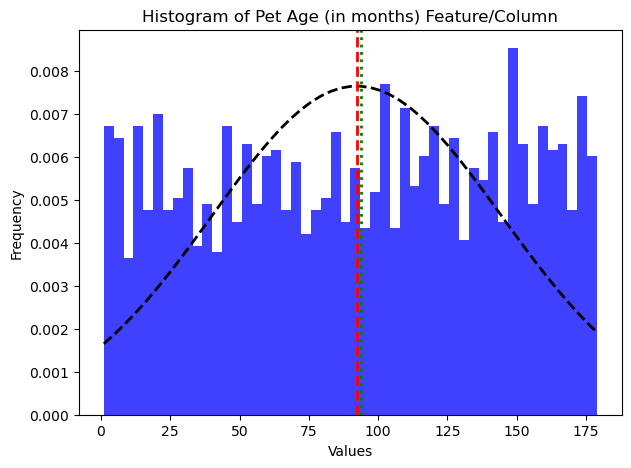

In [60]:
draw_his(df['AgeMonths'])

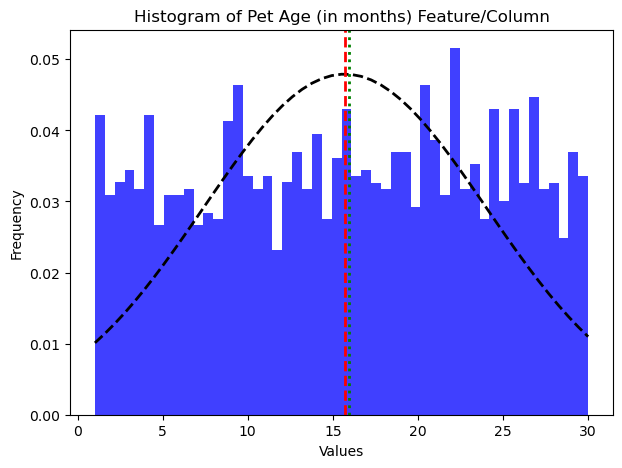

In [61]:
draw_his(df['WeightKg'])

In [66]:
from scipy.stats import gaussian_kde
import numpy as np

In [67]:
def draw_kde(data):
    kde = gaussian_kde(data)

    x = np.linspace(data.min(), data.max(), 500)
    y = kde(x)
    
    plt.figure(figsize=(7, 5))
    plt.plot(x, y)
    
    plt.xlabel("Age (months)")
    plt.ylabel("Density")
    plt.title("KDE of Pet Age")
    
    plt.show()

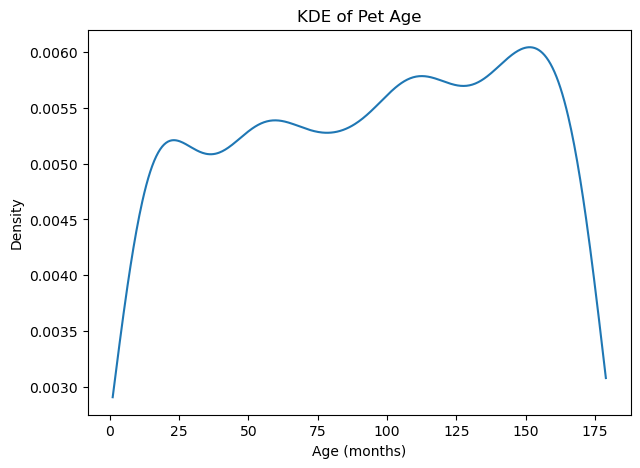

In [68]:
draw_kde(df['AgeMonths'])

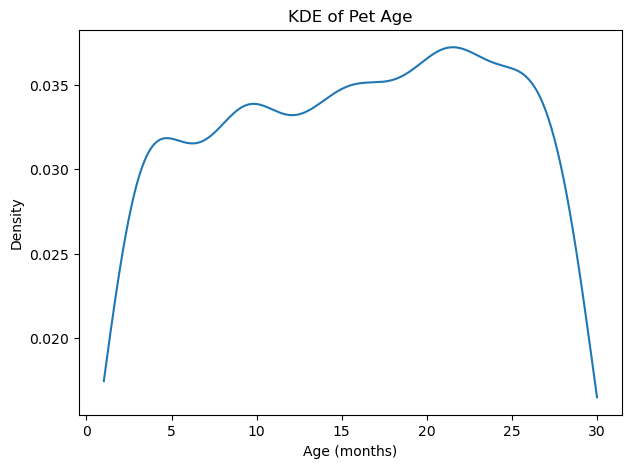

In [69]:
draw_kde(df['WeightKg'])

In [117]:
df.head()

,PetID,PetType,Breed,AgeMonths,Color,Size,WeightKg,Vaccinated,HealthCondition,TimeInShelterDays,AdoptionFee,PreviousOwner,AdoptionLikelihood
0,500,Unknown,Parakeet,131,3,Large,5.039768,1,0,27,140,0,0
1,501,Rabbit,Rabbit,73,4,Large,16.086727,0,0,8,235,0,0
2,502,Dog,Golden Retriever,136,3,Medium,2.076286,0,0,85,385,0,0
3,503,Unknown,Parakeet,97,4,Small,3.339423,0,0,61,217,1,0
4,504,Rabbit,Rabbit,123,2,Large,20.498100,0,0,28,14,1,0


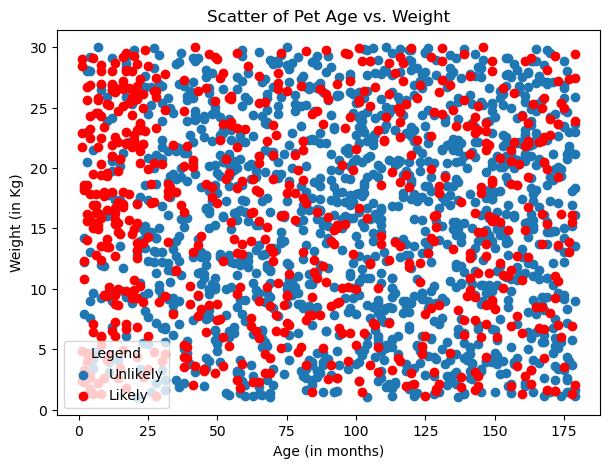

In [72]:
#Sample Scatter Plot
#Setup the figure size for our plot, set number of bins for data granularity, and 
plt.figure(figsize=(7, 5)) 
unlikely = df[df['AdoptionLikelihood'] == 0]
likely = df[df['AdoptionLikelihood'] == 1]

#There are several ways to accomplish the separation of class types, below is drawing two plots in the same frame
#Parameters for color and size are optional and can be adjusted for personal preference
plt.scatter(unlikely['AgeMonths'], unlikely['WeightKg'])  
plt.scatter(likely['AgeMonths'], likely['WeightKg'], c='red')  

#Set the colorbar, titles, labels, grid (optional), and use the .show() to display the scatter plot
plt.legend(title='Legend', labels=['Unlikely','Likely'])
plt.title('Scatter of Pet Age vs. Weight')  
plt.xlabel('Age (in months)')  
plt.ylabel('Weight (in Kg)')
#plt.grid(True)
plt.show()

<Figure size 700x500 with 0 Axes>

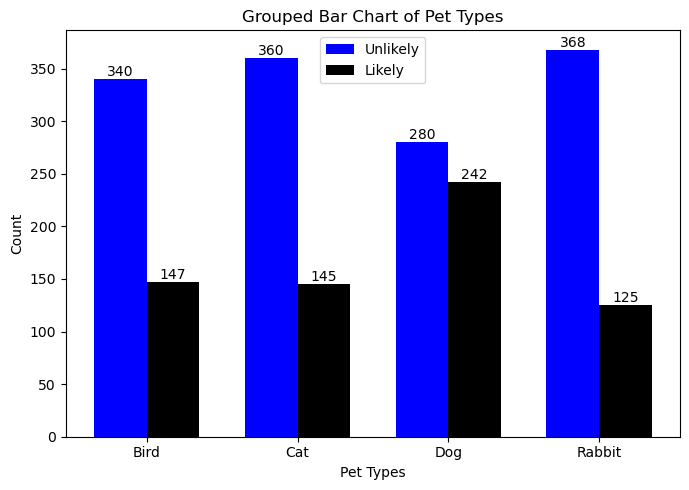

In [75]:
#Sample Bar Graph
#Setup the figure size for our plot, set number of bins for data granularity, and 
plt.figure(figsize=(7, 5)) 
unlikely = df[df['AdoptionLikelihood'] == 0]
likely = df[df['AdoptionLikelihood'] == 1]

# Categories
categories = sorted(df['PetType'].unique())
unlikelyValues = unlikely['PetType'].value_counts().sort_index().values 
likelyValues = likely['PetType'].value_counts().sort_index().values  

# Width of the bars
bar_width = 0.35

# Indices for creating bars
indices = np.arange(len(categories))

# Creating the grouped bar plot
plt.figure(figsize=(7, 5))
unlikelyBars = plt.bar(indices - bar_width/2, unlikelyValues, bar_width, label='Unlikely', color='blue')
likelyBars = plt.bar(indices + bar_width/2, likelyValues, bar_width, label='Likely', color='black')

#Set the colorbar, titles, labels, grid (optional)
plt.legend()
plt.title('Grouped Bar Chart of Pet Types')
plt.xlabel('Pet Types')
plt.ylabel('Count')
plt.xticks(indices, categories)
#plt.grid(True)

# Adding text annotations on top of each bar
def add_labels(bars):
    for bar in bars:
        yval = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, yval, round(yval, 2), ha='center', va='bottom')
add_labels(unlikelyBars)
add_labels(likelyBars)

#Set the param so that the plot fits in to the figure area, and use the .show() to display the bar chart
plt.tight_layout()
plt.show()

In [76]:
# Cleaning

In [78]:
df['PetType'].replace({'Bird': np.nan}, inplace = True)

In [80]:
df.isnull().head()

,PetID,PetType,Breed,AgeMonths,Color,Size,WeightKg,Vaccinated,HealthCondition,TimeInShelterDays,AdoptionFee,PreviousOwner,AdoptionLikelihood
0,False,True,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,True,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False


In [82]:
df.isna().sum()

PetID                   0
PetType               487
Breed                   0
AgeMonths               0
Color                   0
Size                    0
WeightKg                0
Vaccinated              0
HealthCondition         0
TimeInShelterDays       0
AdoptionFee             0
PreviousOwner           0
AdoptionLikelihood      0
dtype: int64

In [84]:
df["PetType"].fillna("Unknown", inplace = True)  
df.head()

,PetID,PetType,Breed,AgeMonths,Color,Size,WeightKg,Vaccinated,HealthCondition,TimeInShelterDays,AdoptionFee,PreviousOwner,AdoptionLikelihood
0,500,Unknown,Parakeet,131,3,Large,5.039768,1,0,27,140,0,0
1,501,Rabbit,Rabbit,73,4,Large,16.086727,0,0,8,235,0,0
2,502,Dog,Golden Retriever,136,3,Medium,2.076286,0,0,85,385,0,0
3,503,Unknown,Parakeet,97,4,Small,3.339423,0,0,61,217,1,0
4,504,Rabbit,Rabbit,123,2,Large,20.498100,0,0,28,14,1,0


In [85]:
df["WeightKg"] = df["WeightKg"].fillna(df["WeightKg"].mean())

In [86]:
mean_weight = df.loc[df["WeightKg"] >= 0, "WeightKg"].mean()

df.loc[df["WeightKg"] < 0, "WeightKg"] = mean_weight

In [87]:
# Cleaning: Duplicate

In [91]:
# PetID   AgeMonths   WeightKg
# 101     24          12.5
# 102     36          18.2
# 103     18          9.5
# 102     36          18.2

In [88]:
df.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
2002    False
2003    False
2004    False
2005    False
2006    False
Length: 2007, dtype: bool

In [89]:
df.duplicated().sum()

0

In [ ]:
df = df.drop_duplicates()

In [92]:
# Duplicate based on column

# PetID   AgeMonths   WeightKg
# 101     24          12.5
# 102     36          18.2
# 102     40          20.1
# 103     18           9.5

In [93]:
df["PetID"].duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
2002    False
2003    False
2004    False
2005    False
2006    False
Name: PetID, Length: 2007, dtype: bool

In [94]:
df = df.drop_duplicates(subset=["PetID"])

In [95]:
# Outliers

In [99]:
from scipy.stats import zscore

z = zscore(df["WeightKg"])

df[abs(z) > 3]

,PetID,PetType,Breed,AgeMonths,Color,Size,WeightKg,Vaccinated,HealthCondition,TimeInShelterDays,AdoptionFee,PreviousOwner,AdoptionLikelihood


In [100]:
Q1 = df["WeightKg"].quantile(0.25)
Q3 = df["WeightKg"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[
    (df["WeightKg"] < lower) |
    (df["WeightKg"] > upper)
]

print(outliers)

Empty DataFrame
Columns: [PetID, PetType, Breed, AgeMonths, Color, Size, WeightKg, Vaccinated, HealthCondition, TimeInShelterDays, AdoptionFee, PreviousOwner, AdoptionLikelihood]
Index: []


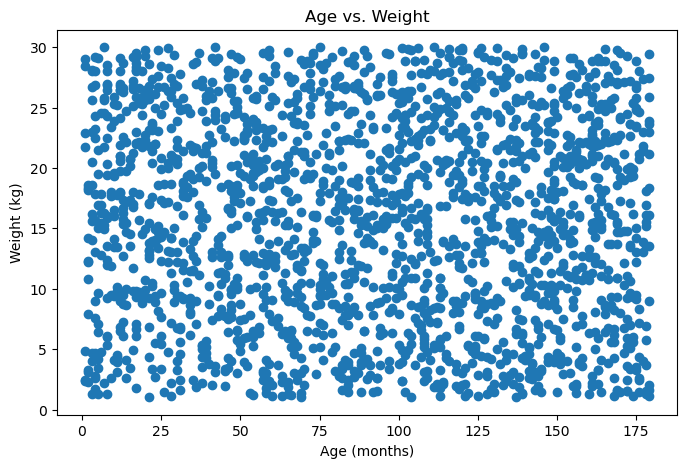

In [103]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["AgeMonths"],
    df["WeightKg"]
)

plt.xlabel("Age (months)")
plt.ylabel("Weight (kg)")
plt.title("Age vs. Weight")

plt.show()

In [105]:
suspicious = df[
    (df["AgeMonths"] > 160) &
    (df["WeightKg"] < 3)
]

print(suspicious)

      PetID  PetType             Breed  AgeMonths  Color    Size  WeightKg  \
26      526      Cat           Persian        172      3   Large  2.435866   
270     770   Rabbit            Rabbit        179      0   Large  1.114838   
338     838      Dog          Labrador        172      2  Medium  1.513702   
340     840      Cat           Persian        179      1   Large  1.629303   
576    1076   Rabbit            Rabbit        161      1  Medium  2.778972   
765    1265  Unknown          Parakeet        178      3   Large  1.501353   
854    1354      Cat           Persian        176      2  Medium  2.586711   
923    1423      Cat           Persian        168      1  Medium  1.141650   
974    1474   Rabbit            Rabbit        176      3   Small  2.431137   
1025   1525   Rabbit            Rabbit        161      2   Small  2.168158   
1081   1581  Unknown          Parakeet        169      0   Large  1.521656   
1099   1599      Dog            Poodle        164      3   Small

In [106]:
petDataRabbits = df[
    df["PetType"] == "Rabbit"
]

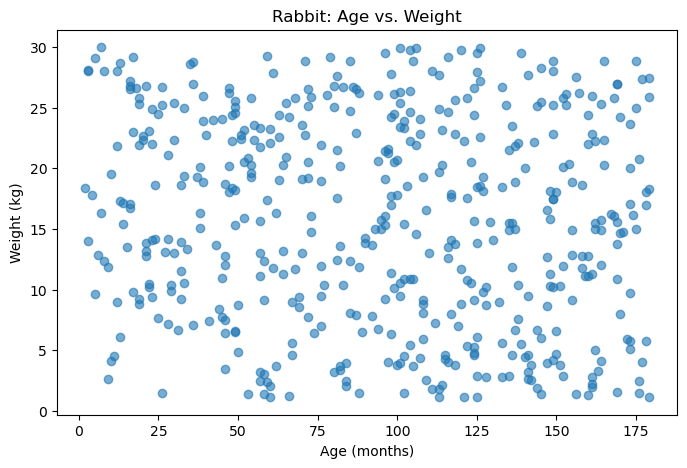

In [107]:
# Scatter plot
plt.figure(figsize=(8, 5))

plt.scatter(
    petDataRabbits["AgeMonths"],
    petDataRabbits["WeightKg"],
    alpha=0.6
)

plt.xlabel("Age (months)")
plt.ylabel("Weight (kg)")
plt.title("Rabbit: Age vs. Weight")

plt.show()

In [109]:
petDataRabbits[
    (petDataRabbits["AgeMonths"] > 175) &
    (petDataRabbits["WeightKg"] < 2)
]

,PetID,PetType,Breed,AgeMonths,Color,Size,WeightKg,Vaccinated,HealthCondition,TimeInShelterDays,AdoptionFee,PreviousOwner,AdoptionLikelihood
270,770,Rabbit,Rabbit,179,0,Large,1.114838,0,0,38,198,1,0
1747,2247,Rabbit,Rabbit,176,4,Medium,1.459753,0,0,66,124,0,0


In [110]:
petDataRabbits[
    (petDataRabbits["AgeMonths"] < 5) &
    (petDataRabbits["WeightKg"] > 12)
]

,PetID,PetType,Breed,AgeMonths,Color,Size,WeightKg,Vaccinated,HealthCondition,TimeInShelterDays,AdoptionFee,PreviousOwner,AdoptionLikelihood
27,527,Rabbit,Rabbit,2,0,Large,18.381399,1,1,84,172,0,0
51,551,Rabbit,Rabbit,3,0,Large,28.098186,0,0,14,490,1,0
510,1010,Rabbit,Rabbit,3,4,Medium,14.023418,0,0,65,412,1,1
1422,1922,Rabbit,Rabbit,4,3,Small,17.813227,1,0,74,57,0,1
1528,2028,Rabbit,Rabbit,3,3,Medium,28.066553,0,1,2,67,0,0


In [111]:
df.drop(df[(df['PetType'] == 'Rabbit') & (df['AgeMonths'] < 5) 
             & (df['WeightKg'] > 12)].index, inplace=True)

In [112]:
df.drop(df[(df['PetType'] == 'Rabbit') & (df['AgeMonths'] > 175) & 
             (df['WeightKg'] < 2)].index, inplace=True)

In [114]:
df.shape

(2000, 13)

In [29]:
#Transformation

In [32]:
le = LabelEncoder()

In [33]:
df['Color'] = le.fit_transform(df['Color'])

In [34]:
df['Color'].value_counts()

Color
4    420
3    409
2    400
0    395
1    383
Name: count, dtype: int64